# RAG 첫 실행 실습: 문서 청크 크기를 바꿔 검색부터 답 검사까지 비교하기

**이 노트북에서 할 일**

1. 02절 크기 500자와 300자로 E01 문서 청크를 두 벌 만들고, 휴관 조건이 어느 문서 청크에 있는지 봅니다.
2. 03~05절 검색·답·검사를 조립 함수 하나로 이어, 500자 색인으로 점검표 한 줄을 만듭니다(실행 1).
3. 문서 청크 크기만 300자로 바꿔 같은 질문을 다시 보내고, 두 점검표를 나란히 봅니다(실행 2).

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 `labs/data/rag-corpus/pdf/easy/E01.pdf`입니다.

인터넷 서비스에 요청을 모두 6번 보냅니다. 임베딩 모델 `text-embedding-3-small`에 4번, `gpt-5.4-mini`에 2번입니다.
임베딩 요청 네 번은 색인 두 번과 검색 두 번입니다. 실행 시간은 1분 안팎입니다.

예상 비용은 0.01달러 미만으로 잡았습니다. 06절보다 요청이 하나 적습니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)에 적힌 100만 토큰당 0.02달러입니다.
mini 요금은 Ch 6 06절에서 확인한 값입니다.

이 노트북은 파일을 만들거나 고치지 않습니다. 06절이 쓴 `runs` 폴더의 기록 파일도 읽거나 건드리지 않습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. pypdf 6.17.0, langchain 1.4.0, langchain-core 1.6.2입니다.
함께 쓰는 판은 langchain-openai 1.6.0과 langchain-text-splitters 1.1.2입니다.
나머지는 openai 3.8.0과 python-dotenv 1.2.3입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch09-rag-first-run`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

01~06절에서 쓴 이름과 문법만 씁니다. 강사와 함께 셀을 차례로 실행하며, 따로 내는 과제는 없습니다.

## 오늘 볼 그림

![맨 위 초록 상자 재료 E01 문서 청크 두 벌 500자 8개와 300자 14개 휴관일 질문 지킬 말 세 개 정답 출처 E01 p.2에서 파란 상자 search_notes 검색 개수 2로 검색해 기록으로 옮기기로 내려가고, 그 아래 보라 상자 text-embedding-3-small, 파란 상자 make_search_row 근거에서 빠진 지킬 말 검색 결과에 없는 정답 출처, 파란 상자 build_notes_messages 메시지 목록 세 개, 보라 상자 gpt-5.4-mini, 파란 상자 add_answer_items 입력 토큰 수 보류 문장 답 검사, 맨 아래 파란 상자 print_rows 검색 뒤 점검표 답 뒤 점검표로 이어지는 위에서 아래 흐름도](attachment:07-1-조립도.png)

위에서 아래로 읽습니다. 맨 위 초록 상자는 노트북 3·4절에서 만드는 재료입니다.
파란 상자 다섯 개는 노트북에서 정의하는 함수이고, 보라 상자 둘은 요청을 받는 모델입니다.
맨 아래 파란 상자가 두 실행의 점검표를 표로 출력합니다. 두 실행은 문서 청크 크기 한 값만 다릅니다.
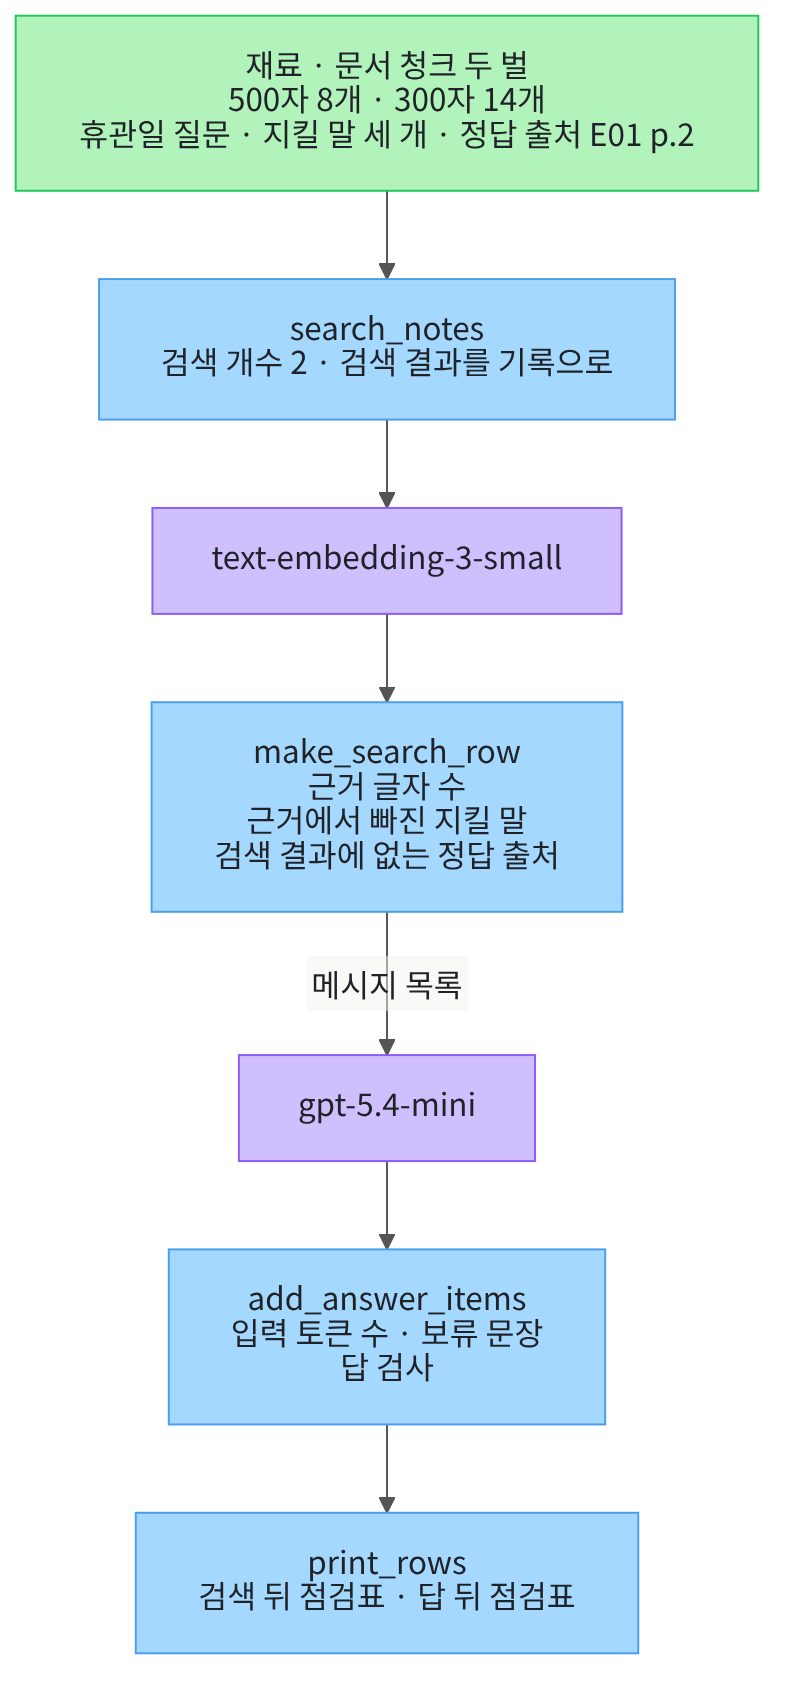

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
05절과 같은 패키지를 씁니다. 06절에서 쓴 PyYAML은 이 실습에서 설정 파일을 읽지 않으므로 빼었습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.17.0" "langchain==1.4.0" "langchain-openai==1.6.0" "langchain-text-splitters==1.1.2" "python-dotenv==1.2.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langchain-text-splitters:", version("langchain-text-splitters"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


pypdf: 6.17.0
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
langchain-text-splitters: 1.1.2
openai: 3.8.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `pypdf: 6.17.0`, `langchain: 1.4.0`, `openai: 3.8.0` 등 일곱 줄입니다.
준비물에 적은 기준 버전과 같습니다.

PDF 읽기, 문서 객체, 글 나누기, 임베딩, 벡터스토어, 모델 준비에 쓸 이름을 불러옵니다. 05절 준비 셀과 같은 이름입니다.

In [2]:
# PDF 읽기·문서 청크 나누기·임베딩·벡터스토어·모델 준비에 쓸 이름을 불러옵니다
import os

from pypdf import PdfReader
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_core.vectorstores import InMemoryVectorStore
from langchain.chat_models import init_chat_model

01·04·05·06절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


04~06절과 같은 설정으로 답을 쓸 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다.
실행마다 답 문장이 달라질 수 있습니다. Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정과 같은 것이 아닙니다.

## 2. 실습 주제 — 문서 청크 크기를 바꿔 검색부터 답 검사까지 비교하기

미르시립도서관 안내 창구에 쓸 색인을 두 가지 크기로 만들어 본다고 봅니다.
02절에서는 크기 500자와 300자로 나눈 문서 청크 수만 세어 보았습니다.
그 크기가 검색 결과와 답, 그리고 05절 검사 결과까지 어떻게 이어지는지는 아직 보지 않았습니다.

이번 실습은 그 한 바퀴를 크기마다 한 번씩 돕니다. 질문은 01·03·04·05절과 같은 휴관일 질문 하나입니다.
검색부터 답 검사까지를 조립 함수 하나로 잇고, 결과를 06절처럼 같은 모양의 점검표 한 줄로 남깁니다.

실행 1은 01~06절과 같은 500자 문서 청크로, 실행 2는 300자 문서 청크로 같은 질문을 보냅니다.
두 실행에서 바꾸는 값은 문서 청크 크기 하나입니다. 겹침 50자, 임베딩 모델, 검색 개수 2, 과업 명세는 같게 둡니다.

06절 설정 파일과 기록 파일, 18건 색인, Ch 11 평가셋 질문은 이번 실습에서 쓰지 않습니다.

## 3. 재료 만들기 — 문서 청크 두 벌

먼저 E01 파일 경로를 고릅니다. 04·05절과 같은 코드입니다.
실행 전에 예상합니다. 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [5]:
# 작업 폴더에서 본 E01.pdf 경로를 후보 세 개 가운데에서 고릅니다
candidates = [
    "labs/data/rag-corpus/pdf/easy/E01.pdf",
    "../../data/rag-corpus/pdf/easy/E01.pdf",
    "../../../data/rag-corpus/pdf/easy/E01.pdf",
]
pdf_path = None
for candidate in candidates:
    if os.path.exists(candidate):
        pdf_path = candidate
        break
print("PDF를 찾았는가:", pdf_path is not None)
print("고른 경로:", pdf_path)
assert pdf_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

PDF를 찾았는가: True
고른 경로: labs/data/rag-corpus/pdf/easy/E01.pdf


**결과 읽기** — 출력 줄은 `PDF를 찾았는가: True`와 `고른 경로: labs/data/rag-corpus/pdf/easy/E01.pdf`입니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

로더 함수 `load_pdf_pages()`는 02~06절과 같은 코드입니다. PDF 경로와 문서 이름을 받아, 쪽마다 Document를 담은 목록을 반환합니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [6]:
# PDF 경로와 문서 이름을 받아, 쪽마다 본문과 메타데이터를 담은 Document 목록을 반환하는 로더 함수를 정의합니다
def load_pdf_pages(pdf_path, doc_id):
    reader = PdfReader(pdf_path)
    page_documents = []
    page_number = 1
    for page in reader.pages:
        metadata = {"doc_id": doc_id, "page": page_number, "source": doc_id + ".pdf"}
        page_document = Document(page_content=page.extract_text(), metadata=metadata)
        page_documents.append(page_document)
        page_number = page_number + 1
    return page_documents

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

다섯 쪽을 읽어 두 가지 크기로 나눕니다. 01~06절과 같은 500자 스플리터와 02절과 같은 300자 스플리터를 씁니다.
겹침은 두 크기 모두 50자입니다. 이름 `small_splitter`와 `small_chunks`는 02절에서 쓴 이름입니다.

실행 전에 예상합니다. 02절처럼 500자에서는 문서 청크 8개, 300자에서는 14개가 될 것입니다.

In [7]:
# E01.pdf 다섯 쪽을 크기 500자와 300자로 각각 나눕니다(요청 없음)
pages = load_pdf_pages(pdf_path, "E01")
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
chunks = splitter.split_documents(pages)
small_splitter = RecursiveCharacterTextSplitter(chunk_size=300, chunk_overlap=50)
small_chunks = small_splitter.split_documents(pages)
print("Document 수:", len(pages))
print("500자 문서 청크 수:", len(chunks))
print("300자 문서 청크 수:", len(small_chunks))

Document 수: 5
500자 문서 청크 수: 8
300자 문서 청크 수: 14


**결과 읽기** — 출력 줄은 `Document 수: 5`, `500자 문서 청크 수: 8`, `300자 문서 청크 수: 14`입니다.
예상대로 02절에서 센 수와 같습니다. 같은 다섯 쪽을 크기만 바꿔 나눈 결과입니다.

## 4. 재료 만들기 — 질문·지킬 말·정답 출처

함수 `make_note()`는 04~06절과 같은 코드입니다. 문서 청크 하나를 받아 출처와 내용을 담은 기록을 반환합니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [8]:
# 문서 청크 하나를 받아, 문서 이름과 쪽 번호로 만든 출처와 본문을 담은 기록을 반환하는 함수를 정의합니다
def make_note(chunk):
    doc_id = chunk.metadata["doc_id"]
    page = chunk.metadata["page"]
    note = {"출처": f"{doc_id} p.{page}", "내용": chunk.page_content}
    return note

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

함수 `find_missing_words()`는 Ch 8 03절과 이 챕터 02·03·05절에서 쓴 코드와 같습니다.
글에 들어 있지 않은 말만 모아 반환합니다. 이 셀도 정의만 합니다.

In [9]:
# 글에 들어 있지 않은 지킬 말만 모아 반환하는 함수를 정의합니다(Ch 8 03절과 같은 코드)
def find_missing_words(text, words):
    missing = []
    for word in words:
        if word not in text:
            missing.append(word)
    return missing

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

질문과 지킬 말, 정답 출처를 담습니다. 질문은 01·03·04·05절과 같은 휴관일 질문입니다.
지킬 말은 Ch 8 03절과 이 챕터 02·05절의 세 말이고, 정답 출처는 05절처럼 사람이 원문을 읽고 적은 쪽입니다.

페르소나와 과업 명세, 보류 문장도 05·06절과 글자까지 같습니다. 검색 개수 2는 두 실행에서 같게 둘 값입니다.

In [10]:
# 05절과 같은 질문·지킬 말·정답 출처·페르소나·과업 명세·보류 문장을 담고, 두 실행에서 같게 둘 검색 개수를 정합니다
closure_question = "미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?"
closure_keep_words = ["월요일", "법정 공휴일", "화요일"]
closure_answer_sources = ["E01 p.2"]
persona_text = "당신은 미르시립도서관 안내 담당자입니다."
task_text = "주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 근거 앞에 붙은 출처 표시를 그대로 적으세요."
task_text = task_text + " 근거에 답이 없으면 추측하지 말고 '제공된 정보로는 확인할 수 없습니다'라고 답하세요."
abstain_sentence = "제공된 정보로는 확인할 수 없습니다"
hit_count = 2
print("질문:", closure_question)
print("지킬 말:", closure_keep_words)
print("정답 출처:", closure_answer_sources)
print("검색 개수:", hit_count)

질문: 미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?
지킬 말: ['월요일', '법정 공휴일', '화요일']
정답 출처: ['E01 p.2']
검색 개수: 2


**결과 읽기** — 출력 줄은 `질문:`으로 시작해 네 줄입니다.
둘째 줄은 `지킬 말: ['월요일', '법정 공휴일', '화요일']`이고, 셋째 줄은 `정답 출처: ['E01 p.2']`입니다.
마지막 줄은 `검색 개수: 2`입니다.

정답 출처는 05절처럼 쪽 단위입니다. E01 2쪽에 휴관 조건이 있다는 것을 사람이 원문에서 읽고 적었습니다.

이제 두 크기에서 휴관 조건이 어느 문서 청크에 들어갔는지 봅니다. 크기마다 지킬 말 세 개가 모두 든 문서 청크를 찾습니다.
검색이 아니라서 요청을 보내지 않습니다.

실행 전에 예상합니다. 크기마다 그런 문서 청크가 하나씩 있고, 둘 다 2쪽일 것입니다.

In [11]:
# 두 크기에서 휴관 지킬 말 세 개가 모두 든 문서 청크를 찾습니다(요청 없음)
print("휴관 지킬 말이 모두 든 문서 청크(문서 청크 크기 | 출처 | 글자 수):")
for chunk_list, chunk_size in [(chunks, 500), (small_chunks, 300)]:
    for chunk in chunk_list:
        note = make_note(chunk)
        missing = find_missing_words(note["내용"], closure_keep_words)
        if missing == []:
            print(chunk_size, "|", note["출처"], "|", len(note["내용"]))

휴관 지킬 말이 모두 든 문서 청크(문서 청크 크기 | 출처 | 글자 수):
500 | E01 p.2 | 498
300 | E01 p.2 | 283


**결과 읽기** — 라벨 줄 아래 두 줄은 `500 | E01 p.2 | 498`과 `300 | E01 p.2 | 283`입니다.
예상대로 크기마다 하나씩이고, 둘 다 E01 2쪽에서 나온 문서 청크입니다.

크기를 300자로 줄이면 2쪽이 네 조각으로 나뉩니다. 휴관 조건은 그 가운데 283자 문서 청크 하나에만 남습니다.
출처는 쪽 번호까지만 적으므로, 2쪽에서 나온 네 문서 청크의 출처는 모두 `E01 p.2`로 같습니다.

## 5. 기록 장치 — 검사 함수와 점검표

검사 함수 세 개를 05절과 같은 코드로 정의합니다. 먼저 `find_cited_notes()`는 답 글에 출처 표시가 든 기록만 모읍니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [12]:
# 답 글에 출처 표시가 들어 있는 기록만 골라 반환하는 함수를 정의합니다(Ch 8 02절과 같은 코드)
def find_cited_notes(answer_text, notes):
    cited = []
    for note in notes:
        mark = "[" + note["출처"] + "]"
        if mark in answer_text:
            cited.append(note)
    return cited

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

함수 `check_answer()`는 Ch 8 04절과 이 챕터 04·05절과 같은 코드입니다.
답의 출처 표시와 같은 기록, 답에서 빠진 지킬 말을 딕셔너리로 반환합니다.
함수 안에서 바깥 이름 `closure_keep_words`를 읽습니다. 이 셀도 정의만 합니다.

In [13]:
# 답 글과 넣은 기록 목록으로, 답의 출처 표시와 같은 기록과 답에서 빠진 지킬 말을 모아 반환하는 함수를 정의합니다
def check_answer(answer_text, notes):
    cited = find_cited_notes(answer_text, notes)
    cited_sources = []
    for note in cited:
        cited_sources.append(note["출처"])
    missing = find_missing_words(answer_text, closure_keep_words)
    check = {"답의 출처 표시와 같은 기록": cited_sources, "답에서 빠진 지킬 말": missing}
    return check

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

함수 `find_missing_sources()`는 05절과 같은 코드입니다. 정답 출처 가운데 검색 출처 목록에 없는 것만 모아 반환합니다.
검색 누락을 찾는 함수입니다. 이 셀도 정의만 합니다.

In [14]:
# 정답 출처 가운데 검색 출처 목록에 없는 것만 모아 반환하는 함수를 정의합니다(05절과 같은 코드)
def find_missing_sources(hit_sources, answer_sources):
    missing = []
    for source in answer_sources:
        if source not in hit_sources:
            missing.append(source)
    return missing

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

점검표를 출력하는 함수를 새로 정의합니다. 점검표 한 줄은 한 실행의 설정과 검색과 답 검사를 담은 딕셔너리입니다.
06절 기록 한 줄과 같은 생각이고, 파일에 쓰지 않고 표로만 봅니다.

표는 두 개입니다. 검색 뒤 점검표에는 답을 받기 전에 확인한 값이, 답 뒤 점검표에는 답을 받은 뒤 확인한 값이 들어갑니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [15]:
# 점검표 목록을 받아 검색 뒤 표와 답 뒤 표를 출력하는 함수를 정의합니다
def print_rows(rows):
    print("검색 뒤 점검표(문서 청크 크기 | 문서 청크 수 | 검색 출처 | 근거 글자 수 | 근거에서 빠진 지킬 말 | 검색 결과에 없는 정답 출처):")
    for row in rows:
        print(row["문서 청크 크기"], "|", row["문서 청크 수"], "|", row["검색 출처"], "|", row["근거 글자 수"], "|", row["근거에서 빠진 지킬 말"], "|", row["검색 결과에 없는 정답 출처"])
    print("답 뒤 점검표(문서 청크 크기 | 입력 토큰 수 | 보류 문장 있음 | 답의 출처 표시와 같은 기록 수 | 답에서 빠진 지킬 말):")
    for row in rows:
        print(row["문서 청크 크기"], "|", row["입력 토큰 수"], "|", row["보류 문장 있음"], "|", row["답의 출처 표시와 같은 기록 수"], "|", row["답에서 빠진 지킬 말"])

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 6. 조립 — 검색부터 답 검사까지 한 함수로

함수 `build_notes_messages()`는 Ch 8 04절과 이 챕터 04~06절과 같은 코드입니다.
기록마다 대괄호 출처 표시와 내용을 이어 user 글을 만듭니다.
함수 안에서 바깥 이름 `persona_text`와 `task_text`를 읽습니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [16]:
# 기록 목록과 질문 하나로 Ch 7 모양의 메시지 목록을 만들어 반환하는 함수를 정의합니다(Ch 8 04절과 같은 코드)
def build_notes_messages(notes, question):
    evidence_text = ""
    for note in notes:
        evidence_text = evidence_text + "[" + note["출처"] + "] " + note["내용"] + "\n"
    user_text = evidence_text + "\n" + "질문: " + question
    messages = [
        ("system", persona_text),
        ("developer", task_text),
        ("user", user_text),
    ]
    return messages

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

조립에 쓸 함수를 세 개 더 정의합니다. 먼저 `search_notes()`는 03절처럼 검색하고 04절처럼 기록으로 옮깁니다.
벡터스토어를 인자로 받으므로, 실행 1과 실행 2에서 다른 색인에 같은 함수를 쓸 수 있습니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [17]:
# 질문과 벡터스토어와 검색 개수를 받아, 검색 결과를 기록 목록으로 옮겨 반환하는 함수를 정의합니다
def search_notes(question_text, question_store, wanted_count):
    # 03절: 질문과 가까운 문서 청크를 검색 개수만큼 가져옵니다(임베딩 요청 1번)
    hits = question_store.similarity_search(question_text, k=wanted_count)
    # 04절: 검색 결과를 출처와 내용을 담은 기록으로 옮깁니다
    notes = []
    for hit in hits:
        note = make_note(hit)
        notes.append(note)
    return notes

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

함수 `make_search_row()`는 답을 받기 전에 두 가지를 검사해 점검표 한 줄을 시작합니다.
하나는 근거 글에서 빠진 지킬 말이고, 다른 하나는 검색 결과에 없는 정답 출처입니다.
근거 글은 기록의 내용만 이어 만들고, 그 글자 수도 같은 줄에 적습니다.
질문 글을 넣으면 질문에 있는 말이 근거에 있는 것처럼 세어지므로 넣지 않습니다.

함수 안에서 바깥 이름 `closure_keep_words`와 `closure_answer_sources`를 읽습니다. 이 셀은 정의만 합니다.

In [18]:
# 기록 목록을 받아, 답을 받기 전에 확인할 값으로 점검표 한 줄을 시작하는 함수를 정의합니다
def make_search_row(notes):
    sources = []
    evidence_text = ""
    for note in notes:
        sources.append(note["출처"])
        evidence_text = evidence_text + note["내용"]
    row = {"검색 출처": sources, "근거 글자 수": len(evidence_text)}
    # 05절 검사 두 개: 근거 글에서 빠진 지킬 말과, 검색 결과에 없는 정답 출처
    row["근거에서 빠진 지킬 말"] = find_missing_words(evidence_text, closure_keep_words)
    row["검색 결과에 없는 정답 출처"] = find_missing_sources(sources, closure_answer_sources)
    return row

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

함수 `add_answer_items()`는 답을 받은 뒤 값을 같은 줄에 더합니다.
더하는 키는 입력 토큰 수, 보류 문장 있음, 답의 출처 표시와 같은 기록 수, 답에서 빠진 지킬 말, 답입니다.
Ch 7 08절 `add_cost_items()`처럼 받은 딕셔너리에 키를 더해 반환합니다.

함수 안에서 바깥 이름 `abstain_sentence`를 읽습니다. 이 셀은 정의만 합니다.

In [19]:
# 점검표 한 줄에 답을 받은 뒤 확인한 값을 더해 반환하는 함수를 정의합니다
def add_answer_items(row, run_response, notes):
    answer_text = run_response.text
    # 04·05절: 답의 출처 표시와 답에서 빠진 지킬 말을 한 번에 검사합니다
    check = check_answer(answer_text, notes)
    row["입력 토큰 수"] = run_response.usage_metadata["input_tokens"]
    row["보류 문장 있음"] = abstain_sentence in answer_text
    row["답의 출처 표시와 같은 기록 수"] = len(check["답의 출처 표시와 같은 기록"])
    row["답에서 빠진 지킬 말"] = check["답에서 빠진 지킬 말"]
    row["답"] = answer_text
    return row

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

마지막으로 조립 함수 `check_question()`을 정의합니다. 질문과 벡터스토어와 검색 개수로 점검표 한 줄을 만듭니다.
줄마다 주석에 가져온 절을 적었습니다.

검색으로 기록을 만들고, 답을 받기 전 검사를 하고, 메시지 목록으로 답을 받고, 답 쪽 값을 같은 줄에 더합니다.
함수 안에서 바깥 이름 `model`을 읽습니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [20]:
# 질문과 벡터스토어와 검색 개수로 검색·답·검사를 차례로 해, 점검표 한 줄을 반환하는 조립 함수를 정의합니다
def check_question(question_text, question_store, wanted_count):
    # 03·04절: 검색 결과를 기록 목록으로 옮깁니다
    notes = search_notes(question_text, question_store, wanted_count)
    # 05절: 답을 받기 전 검사로 점검표 한 줄을 시작합니다
    row = make_search_row(notes)
    # 04절: 기록 목록과 질문으로 메시지 목록을 만들어 답을 받습니다(요청 1번)
    messages = build_notes_messages(notes, question_text)
    run_response = model.invoke(messages)
    # 05절: 답 쪽 검사 결과를 같은 줄에 더합니다
    row = add_answer_items(row, run_response, notes)
    return row

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 7. 실행 1 — 문서 청크 크기 500자

03~05절과 같은 방법으로 빈 벡터스토어를 만들고 500자 문서 청크 8개를 넣습니다.
임베딩 객체 이름은 01·03~06절과 같은 `embedding_model`입니다.

실행 전에 예상합니다. 01~06절처럼 저장 항목 8개가 될 것입니다.

In [21]:
# 500자 문서 청크 8개를 빈 벡터스토어에 넣습니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
embedding_model = OpenAIEmbeddings(model=embedding_model_name)
store = InMemoryVectorStore(embedding=embedding_model)
stored_ids = store.add_documents(chunks)
print("임베딩 모델 이름:", embedding_model_name)
print("넣은 뒤 저장 항목 수:", len(store.store))

임베딩 모델 이름: text-embedding-3-small
넣은 뒤 저장 항목 수: 8


**결과 읽기** — 출력 줄은 `임베딩 모델 이름: text-embedding-3-small`과 `넣은 뒤 저장 항목 수: 8`입니다.
예상대로 01~05절과 같은 8개입니다.

조립 함수를 한 번 불러 점검표 한 줄을 만듭니다. 설정 두 칸은 실행 셀에서 같은 줄에 더합니다.
실행 전에 예상합니다. 01·03절 순위처럼 검색 출처는 표지와 2쪽이고, 근거에 휴관 세 말이 모두 있을 것입니다.

In [22]:
# 실행 1: 500자 색인에서 검색해 답까지 받고, 점검표 한 줄을 출력합니다(임베딩 요청 1번, 답 요청 1번)
run1_row = check_question(closure_question, store, hit_count)
run1_row["문서 청크 크기"] = 500
run1_row["문서 청크 수"] = len(chunks)
print_rows([run1_row])

검색 뒤 점검표(문서 청크 크기 | 문서 청크 수 | 검색 출처 | 근거 글자 수 | 근거에서 빠진 지킬 말 | 검색 결과에 없는 정답 출처):
500 | 8 | ['E01 p.1', 'E01 p.2'] | 543 | [] | []
답 뒤 점검표(문서 청크 크기 | 입력 토큰 수 | 보류 문장 있음 | 답의 출처 표시와 같은 기록 수 | 답에서 빠진 지킬 말):
500 | 513 | False | 1 | ['법정 공휴일']


**결과 읽기** — 검색 뒤 점검표 라벨 줄 아래 한 줄은 `500 | 8 | ['E01 p.1', 'E01 p.2'] | 543 | [] | []`입니다.
예상대로 검색 출처는 표지와 2쪽이고, 근거에서 빠진 지킬 말이 없습니다. 검색 결과에 없는 정답 출처도 없습니다.
근거 글자 수 543은 표지 문서 청크와 2쪽 498자 문서 청크를 이은 길이입니다.

답 뒤 점검표 라벨 줄 아래 한 줄은 `500 | 513 | False | 1 | ['법정 공휴일']`입니다.
입력 토큰 수는 513이고, 보류 문장은 없었습니다.
답의 출처 표시와 같은 기록은 한 개였습니다.

답에서는 지킬 말 `법정 공휴일`이 빠졌습니다. 넣은 근거에는 이 말이 있었으므로 답 쪽에서 빠졌습니다.
01·04·05절 답에서도 같은 말이 빠진 적이 있습니다.

답 글을 따로 출력합니다. 답은 여러 줄일 수 있어 라벨 줄을 앞에 둡니다.

In [23]:
# 실행 1의 답 글을 출력합니다
print("답:")
print(run1_row["답"])

답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. 공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다. [E01 p.2]


**결과 읽기** — 라벨 줄 `답:` 아래 답은 두 문장이고, 끝에 `[E01 p.2]`가 붙었습니다.
첫 문장은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다.`입니다.
둘째 문장은 `공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다.`입니다.

과업 명세는 문장마다 출처 표시를 적게 했지만, 이번 답은 표시를 끝에 한 번만 적었습니다.
01·04절 답에서도 같은 모양이었습니다.

실행마다 답 문장이 달라질 수 있습니다.

## 8. 실행 2 — 문서 청크 크기 300자

문서 청크 크기만 300자로 바꿉니다. 3절에서 만든 `small_chunks`를 새 벡터스토어에 넣습니다.
임베딩 객체는 실행 1과 같은 `embedding_model`을 그대로 씁니다.

실행 전에 예상합니다. 저장 항목은 14개가 될 것입니다.

In [24]:
# 300자 문서 청크 14개를 새 벡터스토어에 넣습니다(임베딩 요청 1번)
small_store = InMemoryVectorStore(embedding=embedding_model)
small_stored_ids = small_store.add_documents(small_chunks)
print("넣은 뒤 저장 항목 수:", len(small_store.store))

넣은 뒤 저장 항목 수: 14


**결과 읽기** — 출력 줄은 `넣은 뒤 저장 항목 수: 14`입니다. 예상대로 300자 문서 청크 수와 같습니다.

같은 질문과 같은 검색 개수로 조립 함수를 한 번 더 부릅니다. 바꾼 값은 문서 청크 크기 하나입니다.

실행 전에 예상합니다. 4절에서 본 283자 문서 청크가 올라오면 근거에 휴관 세 말이 모두 있을 것입니다.
그 문서 청크가 올라오지 않으면 근거에서 세 말이 빠질 것입니다.

In [25]:
# 실행 2: 300자 색인에서 같은 질문을 검색해 답까지 받고, 점검표 한 줄을 출력합니다(임베딩 요청 1번, 답 요청 1번)
run2_row = check_question(closure_question, small_store, hit_count)
run2_row["문서 청크 크기"] = 300
run2_row["문서 청크 수"] = len(small_chunks)
print_rows([run2_row])

검색 뒤 점검표(문서 청크 크기 | 문서 청크 수 | 검색 출처 | 근거 글자 수 | 근거에서 빠진 지킬 말 | 검색 결과에 없는 정답 출처):
300 | 14 | ['E01 p.1', 'E01 p.2'] | 287 | ['월요일', '법정 공휴일', '화요일'] | []
답 뒤 점검표(문서 청크 크기 | 입력 토큰 수 | 보류 문장 있음 | 답의 출처 표시와 같은 기록 수 | 답에서 빠진 지킬 말):
300 | 345 | False | 1 | ['법정 공휴일']


**결과 읽기** — 검색 뒤 점검표 라벨 줄 아래 한 줄은 `300 | 14 | ['E01 p.1', 'E01 p.2'] | 287 | ['월요일', '법정 공휴일', '화요일'] | []`입니다.
검색 출처는 실행 1과 같은 표지와 2쪽입니다. 그런데 근거에서 세 지킬 말이 모두 빠졌습니다.
근거 글자 수는 543에서 287로 줄었습니다. 4절에서 본 283자 문서 청크는 이번 검색에 올라오지 않았습니다.

검색 결과에 없는 정답 출처는 실행 1과 같이 빈 목록입니다. 정답 출처를 쪽 단위로 적었기 때문입니다.
2쪽에서 나온 문서 청크가 하나라도 올라오면 이 검사는 빠진 것이 없다고 봅니다.

답 뒤 점검표 라벨 줄 아래 한 줄은 `300 | 345 | False | 1 | ['법정 공휴일']`입니다.
입력 토큰 수는 513에서 345로 줄었습니다. 근거 글이 543자에서 287자로 짧아졌기 때문입니다.
보류 문장은 이번 실행에서 들어 있지 않았습니다.
나머지 세 칸은 실행 1과 같은 값입니다.

답 글을 따로 출력합니다.

In [26]:
# 실행 2의 답 글을 출력합니다
print("답:")
print(run2_row["답"])

답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. 공휴일이 월요일과 겹치면 휴관일은 다음 날인 화요일로 변경됩니다. [E01 p.2]


**결과 읽기** — 라벨 줄 `답:` 아래 답은 두 문장이고, 끝에 `[E01 p.2]`가 붙었습니다.
첫 문장은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다.`입니다.
둘째 문장은 `공휴일이 월요일과 겹치면 휴관일은 다음 날인 화요일로 변경됩니다.`입니다.

넣은 근거에는 휴관 조건이 없었습니다. 그런데도 답은 휴관일과 화요일을 적었습니다.
모델이 이 내용을 어디에서 가져왔는지는 이 실행으로 알 수 없습니다. Ch 5 07절 뜻의 환각입니다.

01절 2절에서 출력한 E01 2쪽 원문과 대조합니다. 원문은 공휴일이 월요일과 겹치면 화요일에도 휴관한다고 했습니다.
답의 `다음 날인 화요일로 변경됩니다`는 휴관일이 옮겨진다는 뜻으로 읽혀 원문과 다릅니다.

05절에서도 같은 근거로 보낸 답이 실행마다 달랐습니다. 이 답도 실행마다 달라질 수 있습니다.

## 9. 두 실행 비교

두 점검표를 한 번에 출력해 달라진 칸을 봅니다. 앞 줄이 실행 1, 뒤 줄이 실행 2입니다.

실행 전에 예상합니다. 검색 출처와 검색 결과에 없는 정답 출처는 같고, 근거에서 빠진 지킬 말과 답이 다를 것입니다.

In [27]:
# 두 실행의 점검표를 한 번에 출력합니다
print_rows([run1_row, run2_row])

검색 뒤 점검표(문서 청크 크기 | 문서 청크 수 | 검색 출처 | 근거 글자 수 | 근거에서 빠진 지킬 말 | 검색 결과에 없는 정답 출처):
500 | 8 | ['E01 p.1', 'E01 p.2'] | 543 | [] | []
300 | 14 | ['E01 p.1', 'E01 p.2'] | 287 | ['월요일', '법정 공휴일', '화요일'] | []
답 뒤 점검표(문서 청크 크기 | 입력 토큰 수 | 보류 문장 있음 | 답의 출처 표시와 같은 기록 수 | 답에서 빠진 지킬 말):
500 | 513 | False | 1 | ['법정 공휴일']
300 | 345 | False | 1 | ['법정 공휴일']


**결과 읽기** — 검색 뒤 점검표 두 줄의 셋째 칸은 두 줄 모두 `['E01 p.1', 'E01 p.2']`이고, 여섯째 칸은 두 줄 모두 `[]`입니다.
다른 칸은 근거 글자 수 `543`과 `287`, 근거에서 빠진 지킬 말 `[]`과 `['월요일', '법정 공휴일', '화요일']`입니다.

답 뒤 점검표 두 줄은 `500 | 513 | False | 1 | ['법정 공휴일']`과 `300 | 345 | False | 1 | ['법정 공휴일']`입니다.
두 줄은 입력 토큰 수만 다르고, 나머지 세 칸이 같습니다.
답 쪽 검사만 보면 두 실행을 가를 수 없습니다.

## 실험 결과 해석

두 실행은 문서 청크 크기 한 값만 달랐습니다. 크기를 300자로 줄이자 2쪽이 네 조각으로 나뉘었습니다.
검색은 두 실행 모두 표지와 2쪽 문서 청크를 가져왔습니다. 그러나 2쪽에서 올라온 조각의 내용이 달랐습니다.

실행 1의 근거에는 휴관 조건 세 말이 모두 있었고, 답도 그 조건을 적었습니다.
실행 2의 근거에는 세 말이 모두 없었는데, 이번 답도 휴관일과 화요일을 적었습니다.
그 내용을 뒷받침하는 글이 입력에 없습니다.

쪽 단위 검사만 보면 두 실행이 같습니다. 검색 출처는 두 줄 모두 `['E01 p.1', 'E01 p.2']`이고,
검색 결과에 없는 정답 출처도 두 줄 모두 빈 목록입니다. 05절에서 적어 둔 쪽 단위 한계가 이 자리에서 보입니다.

가른 칸은 근거 글을 지킬 말로 검사한 칸입니다. 그 칸이 있어서 답을 받기 전에 근거가 비었다는 것을 알 수 있었습니다.
06절 정답 문서 ID는 문서 단위라, 이보다 더 큰 단위로 봅니다.

입력 토큰 수는 513에서 345로 줄었습니다. 이 차이는 넣은 근거 글이 정한 값입니다.
답 문장과 출력 토큰 수는 같은 근거에서도 요청마다 달라질 수 있습니다.

이 결론은 질문 하나·크기 두 가지·크기마다 한 번 보낸 범위입니다.
어느 크기가 더 좋은지는 한 질문 한 번 실행으로 정할 수 없습니다. 크기를 여러 가지로 늘려 비교하는 일은 Ch 10에서 합니다.

## 정리

- 02절 크기 두 가지, 03절 색인과 검색, 04절 기록과 답, 05절 검사를 조립 함수 `check_question()` 하나로 이었습니다.
- 크기 500자인 실행 1은 근거에 휴관 세 말이 모두 있었고, 답에서는 `법정 공휴일` 하나가 빠졌습니다.
- 크기만 300자로 바꾼 실행 2는 검색 출처가 같았는데도 근거에 세 말이 없었고, 이번 답은 근거에 없는 내용을 적었습니다.

이 절로 Ch 9가 끝납니다. 다음 학습인 Ch 10에서는 문서 형식과 나누는 방법을 여러 가지로 늘려 비교합니다.